In [6]:
import numpy as np
#
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
#
## this next library contains some helper functions for reshaping FATES variables into easier to work with dimensions
import ctsm_py.fates_xarray_funcs as fa       
#
import textwrap
from cmcrameri import cm
import cartopy
import cartopy.crs as ccrs
from cartopy.io.shapereader import Reader
#
import shapefile
from shapely.geometry import shape
import shapely.vectorized


In [7]:
# Shapefile for Amazon ecoregion
Amazon_shapefile='/global/homes/j/jkowalcz/shapefileamazonecoregionwwf/amazon_ecolola.shp'

In [8]:
def make_shapefile_mask(shapefile_path,dataset):
    r = shapefile.Reader(shapefile_path)
    polygon = shape(r.shapes()[0])

    # Standardize longitudes to the -180 to 180 range 
    lon_standardized = ((dataset.lon.values + 180) % 360) - 180

    #Create a 2D grid of your coordinates automatically
    lon_2d, lat_2d = np.meshgrid(lon_standardized, dataset.lat.values)

    #Vectorized polygon check 
    mask_numpy = shapely.vectorized.contains(polygon, lon_2d, lat_2d)

    #Convert it back into a xarray DataArray matching given dataset
    Mask = xr.DataArray(
        mask_numpy.astype(int), 
        coords=[dataset.lat, dataset.lon], 
        dims=["lat", "lon"]
    )

    return Mask

In [9]:
plt.rcParams['figure.constrained_layout.use'] = True
plt.rcParams['figure.autolayout'] = False
plt.rcParams['font.size'] = 14
##plt.rcParams['text.usetex'] = True
plt.rcParams['figure.dpi'] = 300  # Set default DPI to 300 for poster figures


In [37]:
min_lat_plotting = -22.
max_lat_plotting = 12.
min_lon_plotting = 360.-82.
max_lon_plotting = 360.-42.

geog_range_plotting = [min_lon_plotting, max_lon_plotting, min_lat_plotting, max_lat_plotting]


In [10]:
tag='hydro_comp_bmort_kmax_tune_sapflow_kmax3_5xHR_fixSLA_vcmax40.55_fixHR_branch'
path='/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/SummaryFiles/'

file1=tag+'.elm.h2.cat.nc' # should be daily output
daily = xr.open_dataset(path+file1)


In [11]:
fates_Amazon_mask=make_shapefile_mask(Amazon_shapefile,daily)

In [12]:
# want to find the % days with PLC > 60%

# daily average values:
leaf_cf=fa.scpf_to_scls_by_pft(daily.FATES_LEAF_CONDFRAC_SZPF,daily)
stem_cf=fa.scpf_to_scls_by_pft(daily.FATES_STEM_CONDFRAC_SZPF,daily)
troot_cf=fa.scpf_to_scls_by_pft(daily.FATES_TRANSROOT_CONDFRAC_SZPF,daily)
aroot_cf=fa.scpf_to_scls_by_pft(daily.FATES_ABSROOT_CONDFRAC_SZPF,daily)

In [43]:
ba=fa.scpf_to_scls_by_pft(daily.FATES_BASALAREA_SZPF,daily)

In [50]:
early_ba=ba.isel(fates_levpft=0).mean(dim='time')

In [52]:
late_ba=ba.isel(fates_levpft=1).mean(dim='time')

In [27]:
early=xr.concat((leaf_cf.isel(fates_levpft=0),
                 stem_cf.isel(fates_levpft=0),
                 troot_cf.isel(fates_levpft=0),
                 aroot_cf.isel(fates_levpft=0)),dim='array_id')

In [28]:
min_early=early.min(dim="array_id")

In [29]:
late=xr.concat((leaf_cf.isel(fates_levpft=1),
                 stem_cf.isel(fates_levpft=1),
                 troot_cf.isel(fates_levpft=1),
                 aroot_cf.isel(fates_levpft=1)),dim='array_id')

In [31]:
min_late=late.min(dim="array_id")

/global/homes/j/jkowalcz/.conda/envs/myenv/lib/python3.9/site-packages/xarray/plot/facetgrid.py:674: UserWarning: The figure layout has changed to tight
  self.fig.tight_layout()
/tmp/ipykernel_425252/3037500044.py:18: DeprecationWarning: self.axes is deprecated since 2022.11 in order to align with matplotlibs plt.subplots, use self.axs instead.
  for ax in facet.axes.flat:


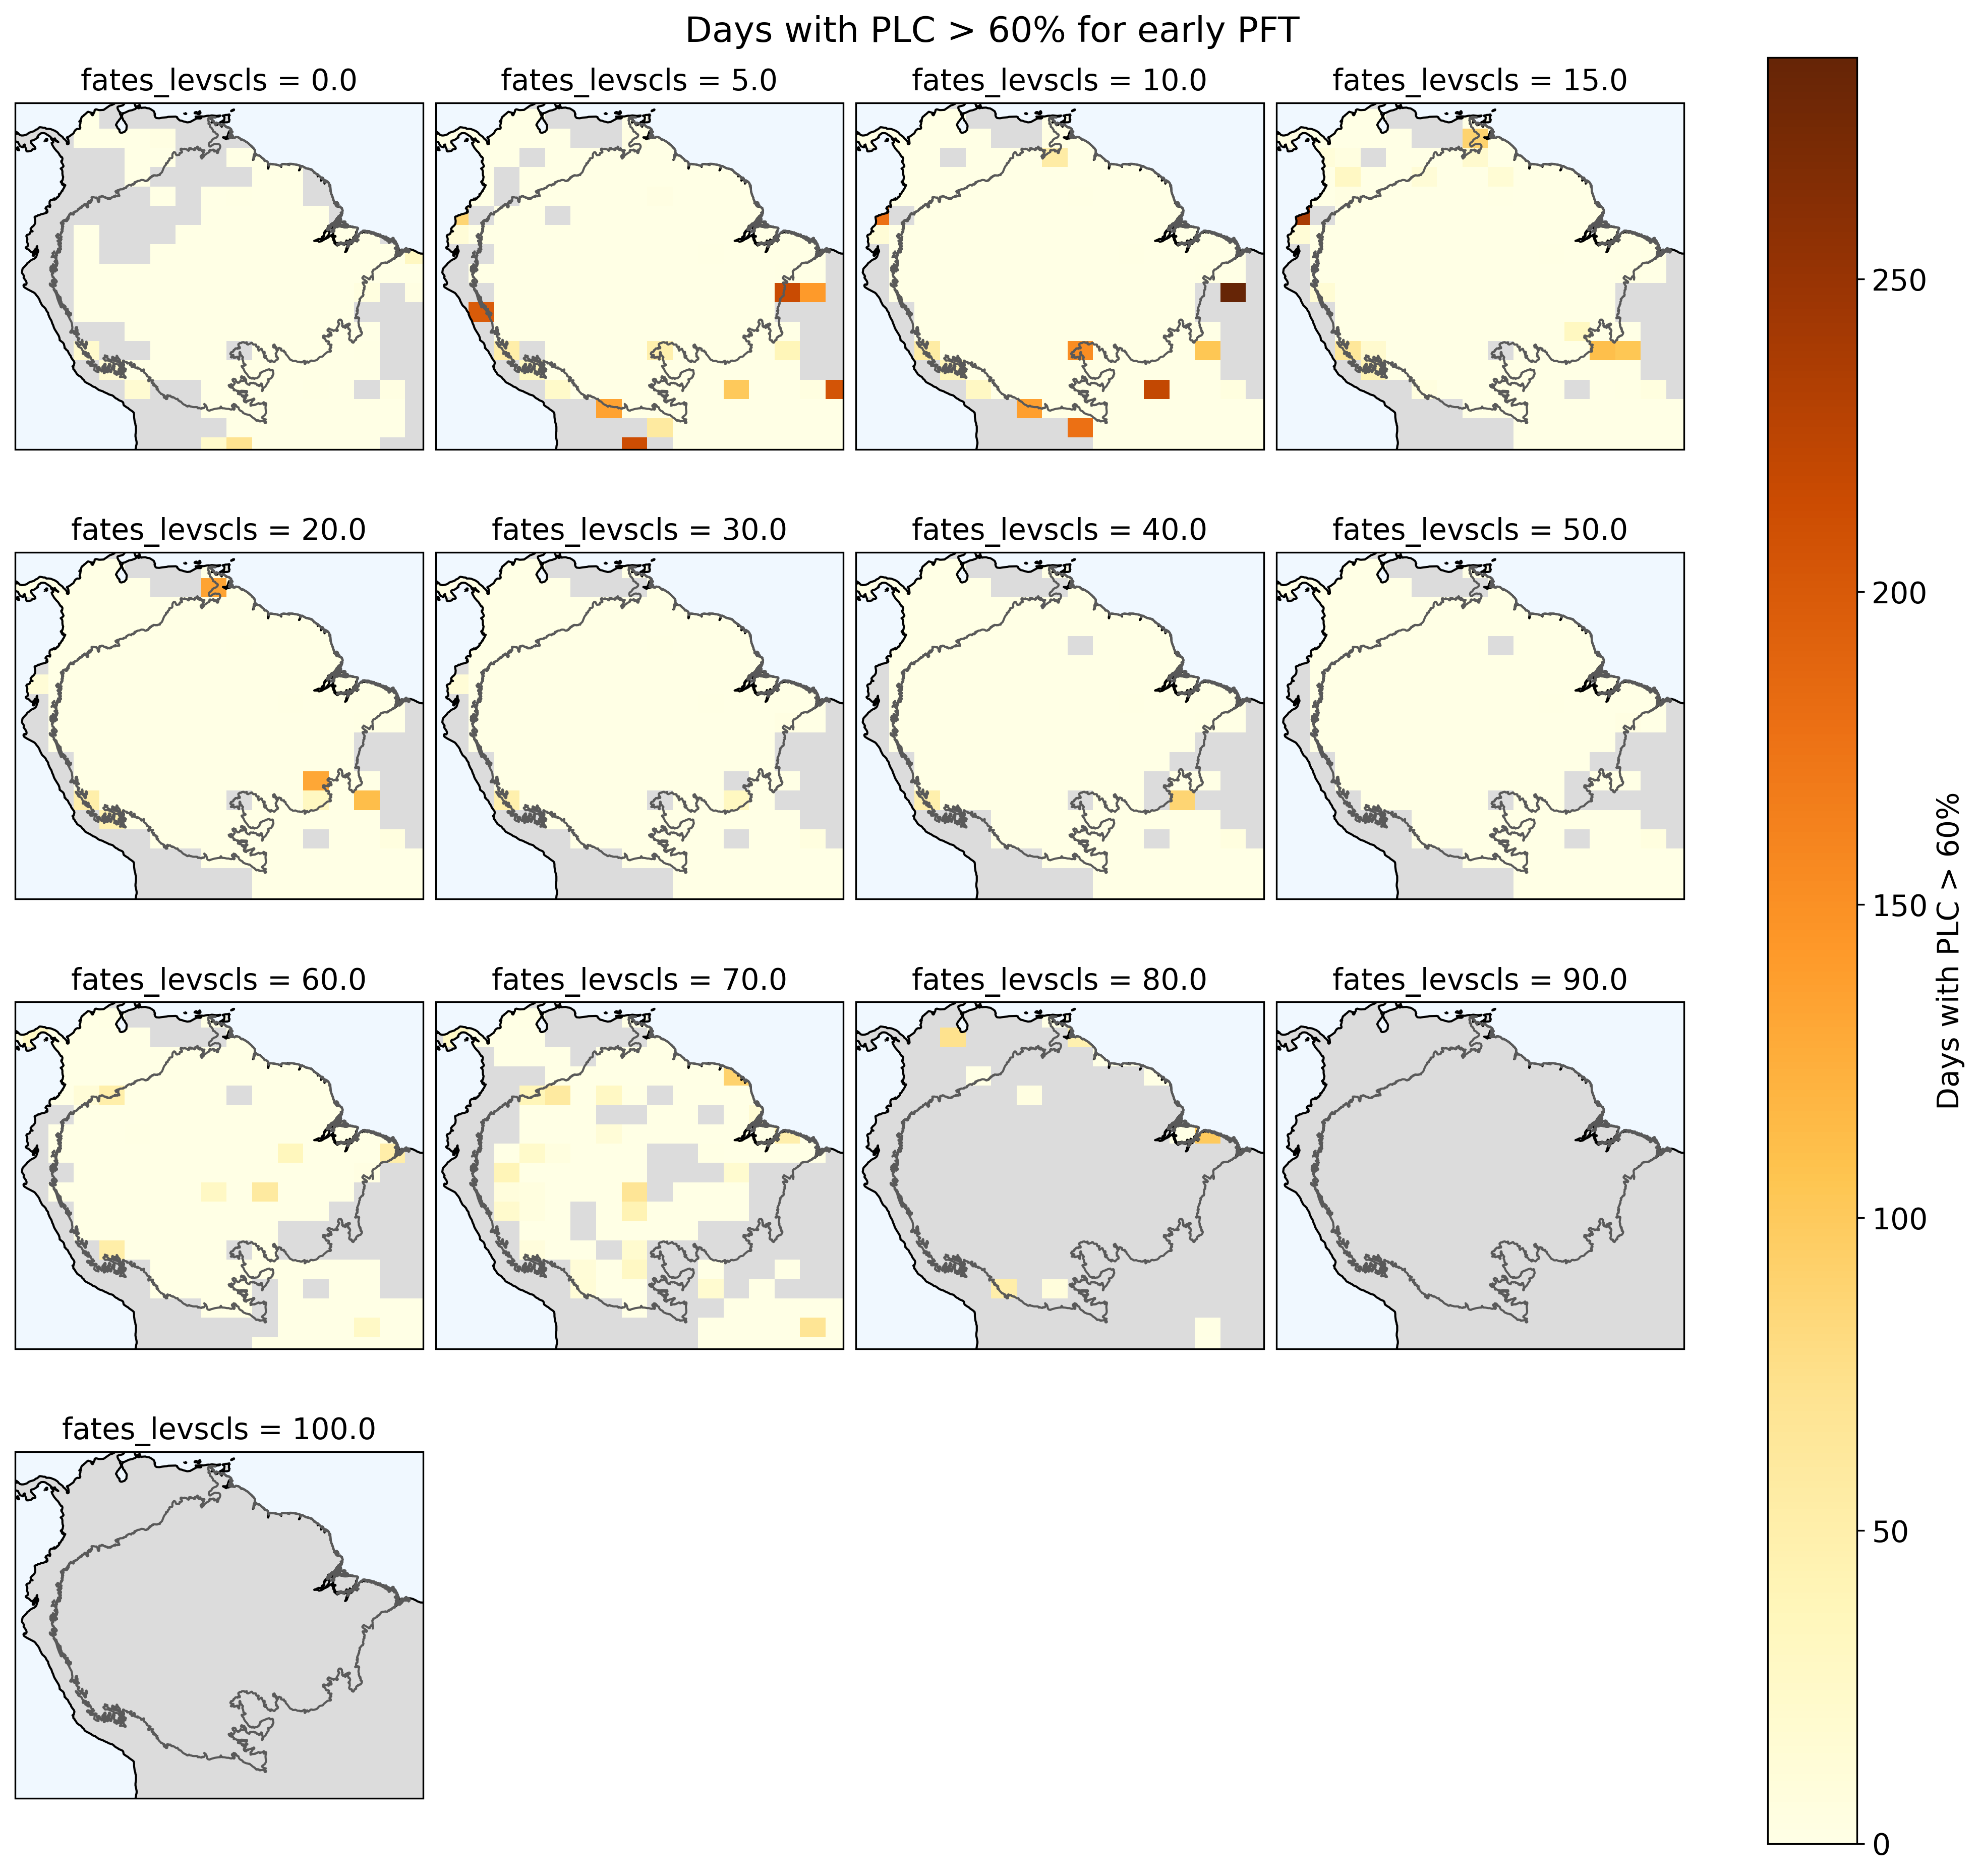

In [58]:
threshold = 0.4

# Count true values along time dimension
# Divide by total number years (25) to get avg days per year
count = (min_early < threshold).sum(dim="time")/25.

# Xarray automatically creates subplots and manages the colorbar
facet = count.where(early_ba > 5.*10**(-6)).plot(
    x="lon",
    y="lat",
    col="fates_levscls",
    col_wrap=4,  # 4 subplots per row
    cmap=plt.cm.YlOrBr,
    cbar_kwargs={"label": f"Days with PLC > 60%"},
    transform=ccrs.PlateCarree(),
    subplot_kws=dict(projection=ccrs.PlateCarree())
)
for ax in facet.axes.flat:
    ax.add_feature(cartopy.feature.LAND, facecolor='gainsboro', zorder=0)
    ax.add_feature(cartopy.feature.OCEAN, facecolor='aliceblue', zorder=1)
    ax.coastlines()
    ax.add_geometries(Reader(Amazon_shapefile).geometries(), ccrs.PlateCarree(), 
                           edgecolor=(0.35,0.35,0.35,1), facecolor=(0,0,0,0))
    ax.set_xlim([min_lon_plotting-360., max_lon_plotting-360.])  #desired longitude range
    ax.set_ylim([min_lat_plotting,max_lat_plotting])  # desired latitude range

facet.fig.suptitle(
    f"Days with PLC > 60% for early PFT", y=1.02
)
plt.show()

/global/homes/j/jkowalcz/.conda/envs/myenv/lib/python3.9/site-packages/xarray/plot/facetgrid.py:674: UserWarning: The figure layout has changed to tight
  self.fig.tight_layout()
/tmp/ipykernel_425252/200772318.py:18: DeprecationWarning: self.axes is deprecated since 2022.11 in order to align with matplotlibs plt.subplots, use self.axs instead.
  for ax in facet.axes.flat:


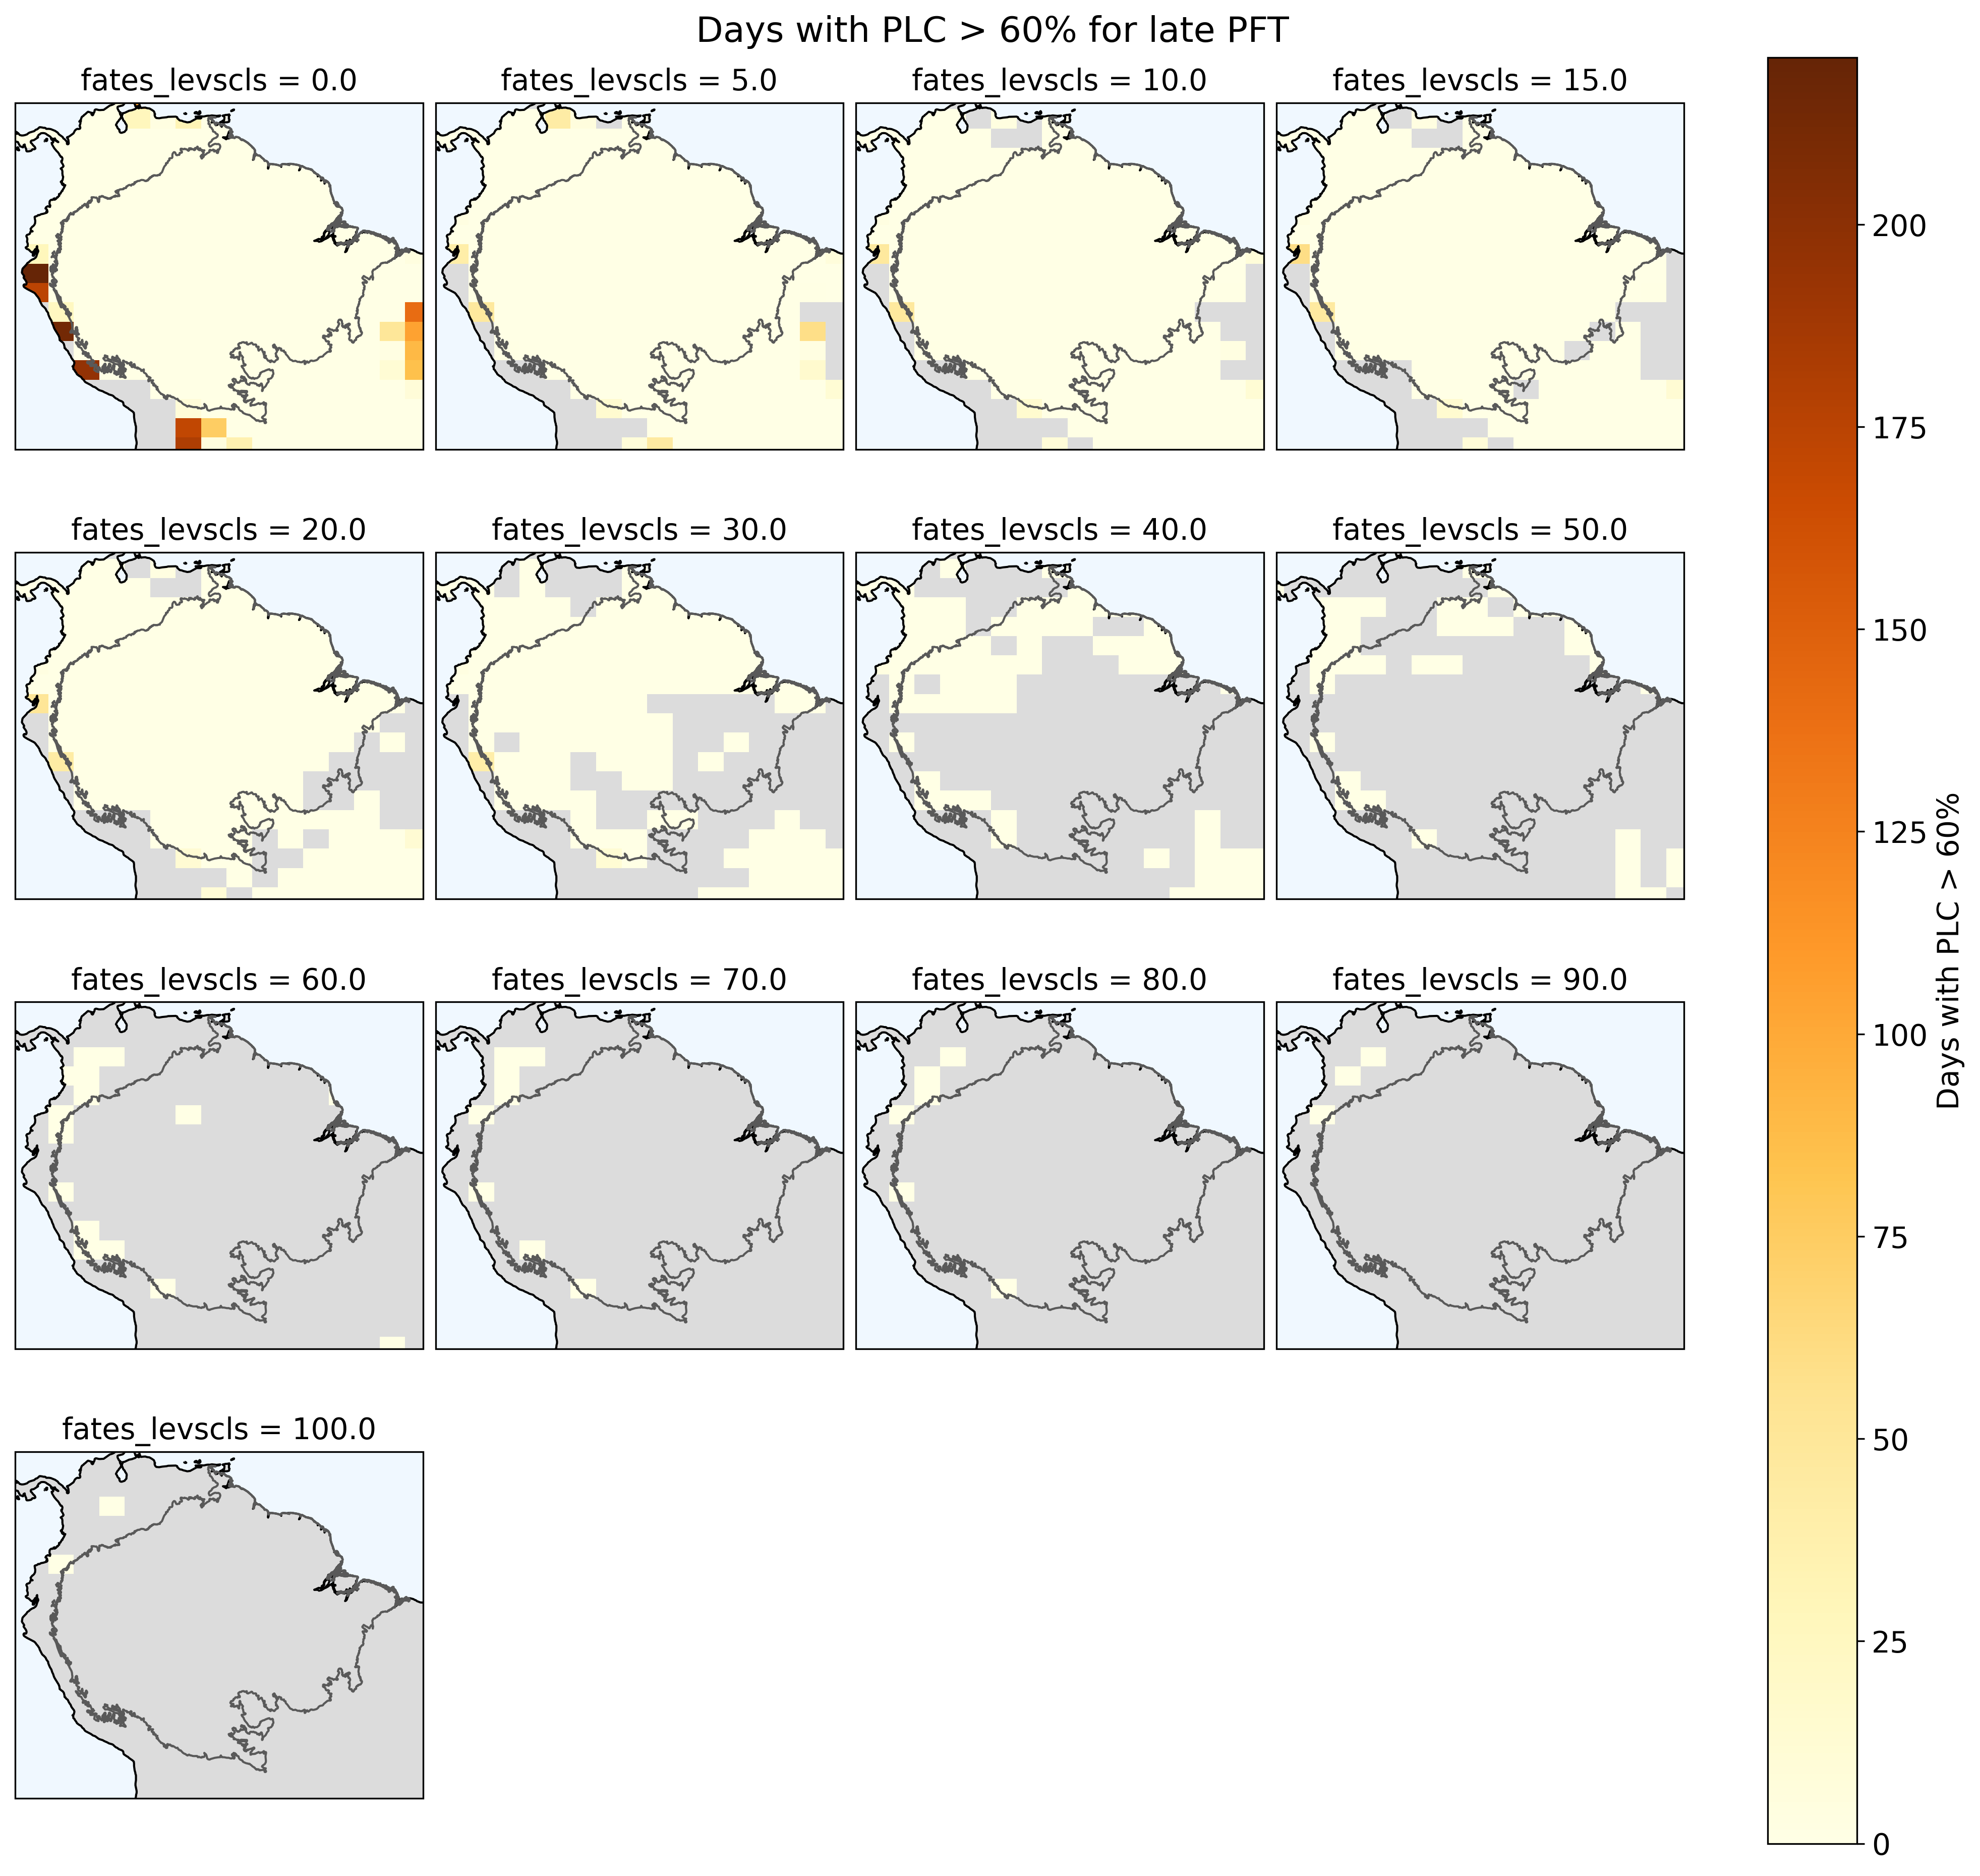

In [57]:
threshold = 0.4

# Count true values along time dimension
# Divide by total number years (25) to get avg days per year
count = (min_late < threshold).sum(dim="time")/25.

# Xarray automatically creates subplots and manages the colorbar
facet = count.where(late_ba > 5.*10**(-6)).plot(
    x="lon",
    y="lat",
    col="fates_levscls",
    col_wrap=4,  # 4 subplots per row
    cmap=plt.cm.YlOrBr,
    cbar_kwargs={"label": f"Days with PLC > 60%"},
    transform=ccrs.PlateCarree(),
    subplot_kws=dict(projection=ccrs.PlateCarree())
)
for ax in facet.axes.flat:
    ax.add_feature(cartopy.feature.LAND, facecolor='gainsboro', zorder=0)
    ax.add_feature(cartopy.feature.OCEAN, facecolor='aliceblue', zorder=1)
    ax.coastlines()
    ax.add_geometries(Reader(Amazon_shapefile).geometries(), ccrs.PlateCarree(), 
                           edgecolor=(0.35,0.35,0.35,1), facecolor=(0,0,0,0))
    ax.set_xlim([min_lon_plotting-360., max_lon_plotting-360.])  #desired longitude range
    ax.set_ylim([min_lat_plotting,max_lat_plotting])  # desired latitude range

facet.fig.suptitle(
    f"Days with PLC > 60% for late PFT", y=1.02
)
plt.show()